# Study 09 · 04 · E3 · Diagnostics on the fixed-hyperparameter models

The paper's secondary diagnostics (Tables III–IV, S1–S8, S11; Figs. 5–7) used the separately **tuned** arms, which differ from the comparator in hyperparameters and have temporal leakage in their tuning (notebook 00). Here the same diagnostics run on the primary arms (`b3_obs`, `historia_geo`) and the two probability baselines, over 18 seasons.

1. CORP decomposition of Brier (miscalibration, discrimination), average precision, calibration slope and intercept. Paper convention: median over seeds within a season, then the mean over seasons.
2. Counts: MAE and RMSE of the published (blended) count, against persistence; WIS of the NB2 interval centred on the published count (four weeks).
3. Net benefit of alerts at thresholds 0.05–0.60, pooled over the 18 seasons.

In [1]:
import os
import sys
from pathlib import Path

os.environ.update({"DENGUEKAY_XGB_DEVICE": "cpu", "DENGUEKAY_XGB_NJOBS": "2", "OMP_NUM_THREADS": "2",
                   "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1", "MLFLOW_DISABLE_AGENT_HINT": "1"})
STUDY = Path.cwd().parent
sys.path.insert(0, str(STUDY / "code"))

import numpy as np
import pandas as pd

import common as c

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt

import experiments as ex

FIG = STUDY / "figures"
RES = c.OUTPUT / "resultados"
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)
base = pd.read_csv(c.OUTPUT / "baselines.csv.gz", dtype={"ubigeo": str}, parse_dates=["semana_inicio", "origen_cierre"])
arms = {"b3": c.read_arm("b3_obs", columns=ex.PRED_COLUMNS), "history+geography": c.read_arm("historia_geo", columns=ex.PRED_COLUMNS)}

## 1 · Probability: CORP, AP, calibration

In [2]:
diag = pd.concat([ex.probability_diagnostics(f, label=name) for name, f in arms.items()]
                 + [ex.probability_diagnostics(base, "persistencia_prob", "probabilistic persistence"),
                    ex.probability_diagnostics(base, "climatologia", "climatology")])
diag.to_csv(RES / "e3_diagnostico_probabilidades.csv", index=False)
summary = ex.summarize_diagnostics(diag)
summary.round(5)

,brazo,horizonte,brier,mcb,dsc,unc,ap,pendiente,intercepto
0,b3,2,0.02824,0.00300,0.03722,0.06244,0.62048,1.09440,-0.37900
1,b3,3,0.03220,0.00359,0.03385,0.06244,0.55817,1.14089,-0.28949
2,b3,4,0.03562,0.00435,0.03116,0.06244,0.50313,1.14370,-0.38940
3,climatology,2,0.06973,0.01552,0.00823,0.06244,0.14388,0.16384,-2.46365
4,climatology,3,0.06975,0.01550,0.00819,0.06244,0.14370,0.16705,-2.42432
5,climatology,4,0.06975,0.01550,0.00819,0.06244,0.14400,0.16770,-2.41399
6,history+geography,2,0.02835,0.00310,0.03719,0.06244,0.62035,1.07552,-0.48144
7,history+geography,3,0.03227,0.00365,0.03386,0.06244,0.55863,1.08999,-0.51064
8,history+geography,4,0.03560,0.00436,0.03120,0.06244,0.50148,1.12996,-0.45489
9,probabilistic persistence,2,0.02863,0.00192,0.03573,0.06244,0.58437,1.10123,0.06827


In [3]:
pooled = []
for name, f in {**arms, "probabilistic persistence": base, "climatology": base}.items():
    column = {"probabilistic persistence": "persistencia_prob", "climatology": "climatologia"}.get(name, "probabilidad_calibrada")
    d = ex.seasons_only(f)
    if "semilla" not in d:
        d["semilla"] = 0
    for (seed, h), g in d.groupby(["semilla", "horizonte"]):
        pooled.append({"brazo": name, "semilla": seed, "horizonte": h, **c.corp(g[column], g.brote)})
pooled = pd.DataFrame(pooled).groupby(["brazo", "horizonte"])[["brier", "mcb", "dsc", "unc"]].median().reset_index()
pooled.to_csv(RES / "e3_corp_agrupado.csv", index=False)
pooled.round(5)

,brazo,horizonte,brier,mcb,dsc,unc
0,b3,2,0.02821,0.00087,0.04266,0.06999
1,b3,3,0.03217,0.00115,0.03896,0.06999
2,b3,4,0.03563,0.00125,0.03564,0.06999
3,climatology,2,0.06968,0.00338,0.00369,0.06999
4,climatology,3,0.06971,0.00337,0.00365,0.06999
5,climatology,4,0.06970,0.00336,0.00366,0.06999
6,history+geography,2,0.02833,0.00093,0.04259,0.06999
7,history+geography,3,0.03226,0.00092,0.03865,0.06999
8,history+geography,4,0.03561,0.00093,0.03532,0.06999
9,probabilistic persistence,2,0.02861,0.00083,0.04221,0.06999


In [4]:
per_season = diag[diag.brazo.isin(["b3", "history+geography"])].groupby(["brazo", "horizonte", "temporada"])[["mcb", "dsc", "ap"]].median().unstack("brazo")
counts = {}
for h in (2, 3, 4):
    d = per_season.loc[h]
    counts[h] = {"seasons where b3 has higher miscalibration": int((d[("mcb", "b3")] > d[("mcb", "history+geography")]).sum()),
                 "seasons where b3 has higher discrimination": int((d[("dsc", "b3")] > d[("dsc", "history+geography")]).sum()),
                 "seasons where b3 has higher AP": int((d[("ap", "b3")] > d[("ap", "history+geography")]).sum())}
pd.DataFrame(counts)

,2,3,4
seasons where b3 has higher miscalibration,8,8,8
seasons where b3 has higher discrimination,8,8,8
seasons where b3 has higher AP,8,9,9


## 2 · Counts

In [5]:
cs = pd.concat([ex.count_scores(f[f.horizonte.eq(4)], name) for name, f in arms.items()]
               + [ex.count_scores(f[f.horizonte.isin([2, 3])], name, with_wis=False) for name, f in arms.items()])
cs.to_csv(RES / "e3_conteos.csv", index=False)
count_summary = (cs.groupby(["brazo", "horizonte", "temporada"]).median(numeric_only=True)
                 .groupby(["brazo", "horizonte"]).mean().drop(columns="semilla"))
count_summary["mae_ratio_vs_persistence"] = count_summary.mae / count_summary.mae_persistencia
count_summary.round(3)

mae    rmse  mae_persistencia    wis  mae_ratio_vs_persistence
brazo             horizonte                                                                  
b3                2          1.730   8.961             1.920    NaN                     0.901
                  3          2.177  11.502             2.511    NaN                     0.867
                  4          2.560  13.454             3.008  1.888                     0.851
history+geography 2          1.801   9.429             1.920    NaN                     0.938
                  3          2.323  12.279             2.511    NaN                     0.925
                  4          2.781  14.653             3.008  1.967                     0.924

## 3 · Net benefit of alerts (pooled over 18 seasons)

In [6]:
nb = pd.concat([ex.net_benefit(f, "probabilidad_calibrada", label=name) for name, f in arms.items()]
               + [ex.net_benefit(base, "persistencia_prob", label="probabilistic persistence")])
nb.to_csv(RES / "e3_beneficio_neto.csv", index=False)
# Pool across seasons weighting by district-weeks (each season has ~3,400 rows): mean over seasons of the seed median.
nb_summary = nb.groupby(["brazo", "horizonte", "umbral", "temporada"]).beneficio_neto.median().groupby(["brazo", "horizonte", "umbral"]).mean().unstack("brazo")
wins = (nb.groupby(["brazo", "horizonte", "umbral", "temporada"]).beneficio_neto.median().unstack("brazo"))
wins = (wins["b3"] > wins["probabilistic persistence"]).groupby(["horizonte", "umbral"]).sum().rename("seasons b3 > persistence")
nb_summary.join(wins).loc[4].round(5)

,b3,history+geography,probabilistic persistence,seasons b3 > persistence
umbral,,,,
0.05,0.06310,0.06313,0.05807,11
0.10,0.05666,0.05627,0.05237,11
0.15,0.05173,0.05148,0.04680,10
0.20,0.04789,0.04738,0.04372,10
0.25,0.04411,0.04400,0.04043,10
0.30,0.04124,0.04106,0.03710,7
0.35,0.03785,0.03779,0.03509,8
0.40,0.03477,0.03466,0.03254,7
0.45,0.03099,0.03120,0.03011,4


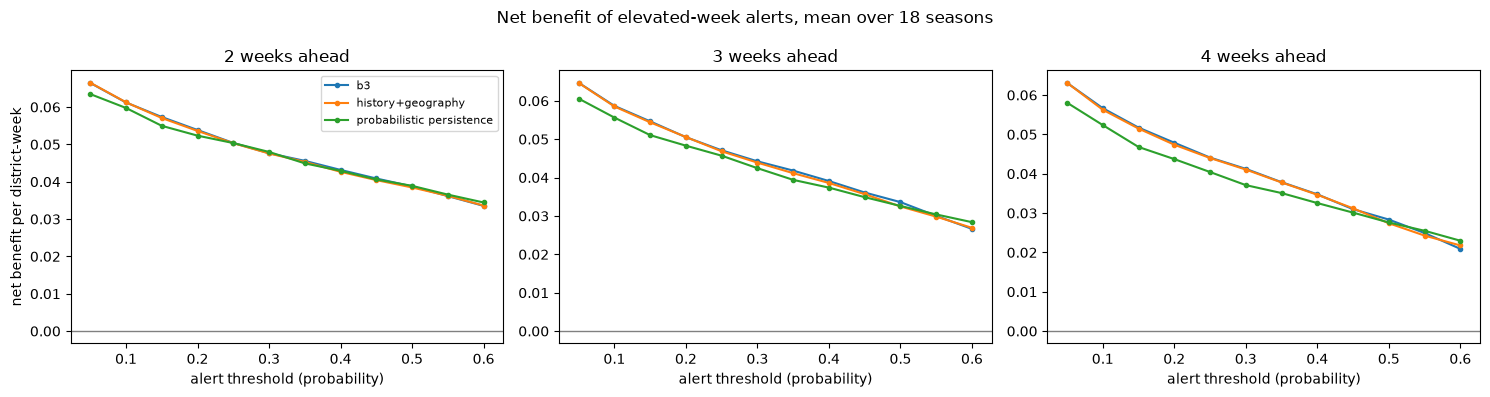

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, h in zip(axes, (2, 3, 4)):
    d = nb_summary.loc[h]
    for col in d.columns:
        ax.plot(d.index, d[col], marker="o", ms=3, label=col)
    ax.axhline(0, color="0.5", lw=1)
    ax.set_title(f"{h} weeks ahead")
    ax.set_xlabel("alert threshold (probability)")
axes[0].set_ylabel("net benefit per district-week")
axes[0].legend(fontsize=8)
fig.suptitle("Net benefit of elevated-week alerts, mean over 18 seasons")
fig.tight_layout()
fig.savefig(FIG / "e3_beneficio_neto.png", dpi=160)